# Task 3: Professional Data Cleaning and Preprocessing

## Objective

This notebook inspects and cleans the supplied cafe sales CSV. Every transformation is based on observed values, preserves the original dataset, and produces a separate analysis-ready CSV.

## Dataset context

The dataset contains one row per cafe transaction with an identifier, product, quantity, unit price, total amount, payment method, location, and transaction date. Sentinel values such as `ERROR` and `UNKNOWN` are treated as missing only after they are measured in the quality report.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

project_root = next((candidate for candidate in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent) if (candidate / 'data' / 'dirty_cafe_sales.csv').exists()), Path.cwd())
input_path = project_root / 'data' / 'dirty_cafe_sales.csv'
output_dir = project_root / 'output'
charts_dir = output_dir / 'charts'
output_dir.mkdir(exist_ok=True)
charts_dir.mkdir(exist_ok=True)
assert input_path.exists(), f'Expected dataset was not found: {input_path}'
print(f'Project root: {project_root.resolve()}')
print(f'Input dataset: {input_path.resolve()}')

Project root: /Users/atifnawaz/Retail_Sales_EDA/Retail_Sales_EDA/DataAnalytics-L1-Task3-DataCleaning
Input dataset: /Users/atifnawaz/Retail_Sales_EDA/Retail_Sales_EDA/DataAnalytics-L1-Task3-DataCleaning/data/dirty_cafe_sales.csv


## 1. Load Dataset and Initial Inspection

In [2]:
raw = pd.read_csv(input_path, dtype='string')
before_rows, before_columns = raw.shape
print('First five rows:')
display(raw.head())
print('Last five rows:')
display(raw.tail())
print(f'Dimensions: {before_rows:,} rows x {before_columns} columns')
print('Column names:', raw.columns.tolist())
print('Data types:')
display(raw.dtypes.to_frame('dtype'))
print('Dataset info:')
raw.info()
print('Descriptive statistics:')
display(raw.describe(include='all').transpose())

First five rows:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


Last five rows:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9995,TXN_7672686,Coffee,2,2.0,4.0,<NA>,UNKNOWN,2023-08-30
9996,TXN_9659401,<NA>,3,<NA>,3.0,Digital Wallet,<NA>,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,<NA>,2023-03-02
9998,TXN_7695629,Cookie,3,<NA>,3.0,Digital Wallet,<NA>,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


Dimensions: 10,000 rows x 8 columns
Column names: ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']
Data types:


,dtype
Transaction ID,string
Item,string
Quantity,string
Price Per Unit,string
Total Spent,string
Payment Method,string
Location,string
Transaction Date,string


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  string
 1   Item              9667 non-null   string
 2   Quantity          9862 non-null   string
 3   Price Per Unit    9821 non-null   string
 4   Total Spent       9827 non-null   string
 5   Payment Method    7421 non-null   string
 6   Location          6735 non-null   string
 7   Transaction Date  9841 non-null   string
dtypes: string(8)
memory usage: 625.1 KB
Descriptive statistics:


,count,unique,top,freq
Transaction ID,10000,10000,TXN_1961373,1
Item,9667,10,Juice,1171
Quantity,9862,7,5,2013
Price Per Unit,9821,8,3.0,2429
Total Spent,9827,19,6.0,979
Payment Method,7421,5,Digital Wallet,2291
Location,6735,4,Takeaway,3022
Transaction Date,9841,367,UNKNOWN,159


## 2. Data Quality Report Before Cleaning

In [3]:
sentinel_values = {'ERROR', 'UNKNOWN', ''}
numeric_columns = ['Quantity', 'Price Per Unit', 'Total Spent']
date_column = 'Transaction Date'
categorical_columns = ['Item', 'Payment Method', 'Location']

quality_rows = []
for column in raw.columns:
    series = raw[column]
    explicit_missing = int(series.isna().sum())
    sentinel_missing = int(series.fillna('').isin(sentinel_values).sum() - series.isna().sum())
    if column in numeric_columns:
        converted = pd.to_numeric(series, errors='coerce')
        parse_failures = int((series.notna() & converted.isna()).sum())
        range_text = f'{converted.min()} to {converted.max()}'
    elif column == date_column:
        converted = pd.to_datetime(series, errors='coerce')
        parse_failures = int((series.notna() & converted.isna()).sum())
        range_text = f'{converted.min()} to {converted.max()}'
    else:
        parse_failures = 0
        range_text = 'categorical/text'
    quality_rows.append({
        'column': column,
        'dtype_before': str(series.dtype),
        'explicit_missing': explicit_missing,
        'sentinel_values': sentinel_missing,
        'missing_percent': (explicit_missing + sentinel_missing) / len(raw) * 100,
        'parse_failures': parse_failures,
        'observed_range': range_text,
        'unique_values': int(series.nunique(dropna=True)),
    })
quality_report = pd.DataFrame(quality_rows)
print(f'Exact duplicate rows before cleaning: {raw.duplicated().sum():,}')
display(quality_report)
print('Categorical values requiring investigation:')
for column in categorical_columns:
    print(f'\n{column}:')
    display(raw[column].value_counts(dropna=False).head(20).to_frame('count'))

Exact duplicate rows before cleaning: 0


,column,dtype_before,explicit_missing,sentinel_values,missing_percent,parse_failures,observed_range,unique_values
0,Transaction ID,string,0,0,0.00,0,categorical/text,10000
1,Item,string,333,636,9.69,0,categorical/text,10
2,Quantity,string,138,341,4.79,341,1 to 5,7
3,Price Per Unit,string,179,354,5.33,354,1.0 to 5.0,8
4,Total Spent,string,173,329,5.02,329,1.0 to 25.0,19
5,Payment Method,string,2579,599,31.78,0,categorical/text,5
6,Location,string,3265,696,39.61,0,categorical/text,4
7,Transaction Date,string,159,301,4.60,301,2023-01-01 00:00:00 to 2023-12-31 00:00:00,367


Categorical values requiring investigation:

Item:


,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089
UNKNOWN,344



Payment Method:


,count
Payment Method,
<NA>,2579
Digital Wallet,2291
Credit Card,2273
Cash,2258
ERROR,306
UNKNOWN,293



Location:


,count
Location,
<NA>,3265
Takeaway,3022
In-store,3017
ERROR,358
UNKNOWN,338


## 3. Missing Data Analysis and Handling

Cleaning decisions are column-specific:

- `Transaction ID` is an identifier and is not imputed. It has no missing values.
- `Item`, `Payment Method`, and `Location` use their observed mode after sentinel values are converted to missing. This preserves rows while using the most common valid category.
- `Quantity` uses the median because it is numeric and bounded; the median is less sensitive to skew or unusual values.
- `Price Per Unit` uses the median for the same robustness reason.
- `Transaction Date` uses the median valid date because the dataset has a one-year transaction period and no ordering key that would justify forward fill.
- `Total Spent` is reconstructed as `Quantity * Price Per Unit` after those fields are complete. This respects the business relationship instead of independently imputing a dependent measure.

In [4]:
cleaned = raw.copy()
for column in cleaned.columns:
    cleaned[column] = cleaned[column].str.strip()
    cleaned[column] = cleaned[column].replace(list(sentinel_values), pd.NA)

missing_before = cleaned.isna().sum().rename('missing_before')
print('Missing values after sentinel normalization and before imputation:')
display(missing_before.to_frame())

for column in ['Item', 'Payment Method', 'Location']:
    fill_value = cleaned[column].mode(dropna=True).iloc[0]
    cleaned[column] = cleaned[column].fillna(fill_value)
    print(f'{column}: filled missing values with mode {fill_value!r}')

for column in ['Quantity', 'Price Per Unit']:
    cleaned[column] = pd.to_numeric(cleaned[column], errors='coerce')
    fill_value = cleaned[column].median()
    cleaned[column] = cleaned[column].fillna(fill_value)
    print(f'{column}: filled missing values with median {fill_value}')

cleaned[date_column] = pd.to_datetime(cleaned[date_column], errors='coerce')
date_fill = cleaned[date_column].median()
cleaned[date_column] = cleaned[date_column].fillna(date_fill)
print(f'{date_column}: filled missing values with median date {date_fill.date()}')

cleaned['Total Spent'] = pd.to_numeric(cleaned['Total Spent'], errors='coerce')
total_missing = cleaned['Total Spent'].isna()
cleaned.loc[total_missing, 'Total Spent'] = cleaned.loc[total_missing, 'Quantity'] * cleaned.loc[total_missing, 'Price Per Unit']
print(f'Total Spent: reconstructed {int(total_missing.sum()):,} missing values from Quantity x Price Per Unit')
print('Missing values after treatment:')
display(cleaned.isna().sum().rename('missing_after').to_frame())

Missing values after sentinel normalization and before imputation:


,missing_before
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


Item: filled missing values with mode 'Juice'
Payment Method: filled missing values with mode 'Digital Wallet'
Location: filled missing values with mode 'Takeaway'
Quantity: filled missing values with median 3.0
Price Per Unit: filled missing values with median 3.0
Transaction Date: filled missing values with median date 2023-07-02
Total Spent: reconstructed 502 missing values from Quantity x Price Per Unit
Missing values after treatment:


,missing_after
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


## 4. Duplicate Detection and Removal

Only exact duplicate rows are removed. Rows sharing an identifier would not be removed unless every field matched.

In [5]:
duplicate_count_before = int(cleaned.duplicated().sum())
cleaned = cleaned.drop_duplicates().reset_index(drop=True)
rows_removed = duplicate_count_before
print(f'Exact duplicates before removal: {duplicate_count_before:,}')
print(f'Rows removed: {rows_removed:,}')
print(f'Exact duplicates after removal: {cleaned.duplicated().sum():,}')

Exact duplicates before removal: 0
Rows removed: 0
Exact duplicates after removal: 0


## 5. Standardisation and Data Type Correction

Text values are trimmed, sentinel values are handled as missing, dates are converted to pandas datetime, identifiers remain strings, and measures become numeric. No categorical or identifier column is treated as an outlier.

In [6]:
expected_types = {
    'Transaction ID': 'string',
    'Item': 'string',
    'Quantity': 'Int64',
    'Price Per Unit': 'float64',
    'Total Spent': 'float64',
    'Payment Method': 'string',
    'Location': 'string',
    'Transaction Date': 'datetime64[ns]',
}
cleaned['Transaction ID'] = cleaned['Transaction ID'].astype('string')
cleaned['Item'] = cleaned['Item'].astype('string')
cleaned['Payment Method'] = cleaned['Payment Method'].astype('string')
cleaned['Location'] = cleaned['Location'].astype('string')
cleaned['Quantity'] = cleaned['Quantity'].round().astype('Int64')
cleaned['Price Per Unit'] = cleaned['Price Per Unit'].astype('float64')
cleaned['Total Spent'] = cleaned['Total Spent'].astype('float64')
cleaned['Transaction Date'] = pd.to_datetime(cleaned['Transaction Date'])

type_check = pd.DataFrame({
    'expected_type': pd.Series(expected_types),
    'actual_type': cleaned[list(expected_types)].dtypes.astype(str),
})
type_check['matches'] = type_check['expected_type'] == type_check['actual_type']
display(type_check)
print('Examples of standardized categorical values:')
display(cleaned[['Item', 'Payment Method', 'Location']].head())

,expected_type,actual_type,matches
Transaction ID,string,string,True
Item,string,string,True
Quantity,Int64,Int64,True
Price Per Unit,float64,float64,True
Total Spent,float64,float64,True
Payment Method,string,string,True
Location,string,string,True
Transaction Date,datetime64[ns],datetime64[us],False


Examples of standardized categorical values:


,Item,Payment Method,Location
0,Coffee,Credit Card,Takeaway
1,Cake,Cash,In-store
2,Cookie,Credit Card,In-store
3,Salad,Digital Wallet,Takeaway
4,Coffee,Digital Wallet,In-store


## 6. Outlier Detection and Treatment

The IQR rule is applied only to the three numeric measures. Potential outliers are retained because quantities and prices are valid positive business values in this cafe dataset; deleting them would remove legitimate transactions. The notebook reports detected values separately from values removed or capped (zero).

,column,Q1,Q3,IQR,lower_bound,upper_bound,potential_outliers,treatment
0,Quantity,2.00,4.00,2.00,-1.00,7.00,0,Retained; no values removed or capped
1,Price Per Unit,2.00,4.00,2.00,-1.00,7.00,0,Retained; no values removed or capped
2,Total Spent,4.00,12.00,8.00,-8.00,24.00,268,Retained; no values removed or capped


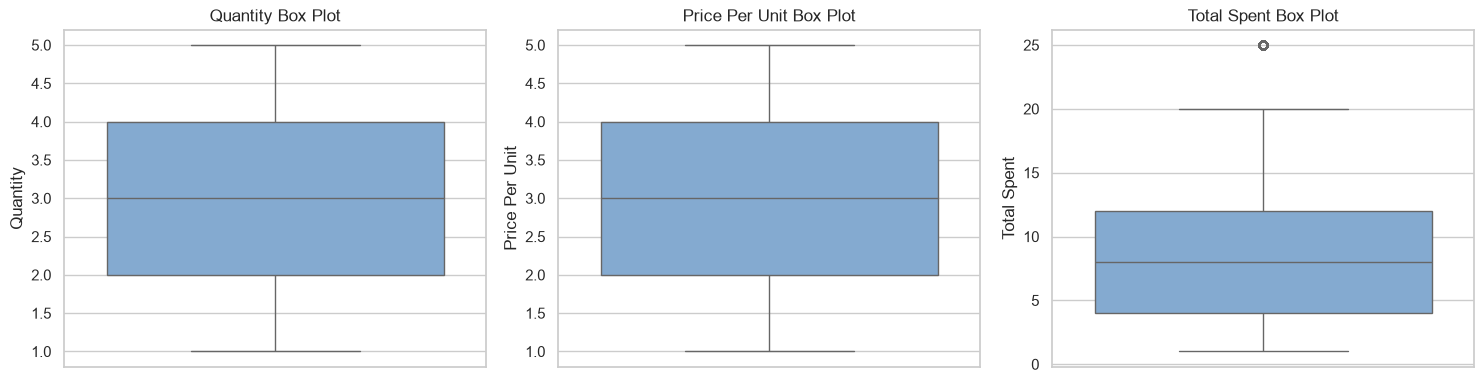

In [7]:
outlier_rows = []
for column in numeric_columns:
    series = cleaned[column].astype(float)
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({'column': column, 'Q1': q1, 'Q3': q3, 'IQR': iqr, 'lower_bound': lower, 'upper_bound': upper, 'potential_outliers': count, 'treatment': 'Retained; no values removed or capped'})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
potential_outliers_total = int(outlier_summary['potential_outliers'].sum())
outliers_removed_or_capped = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, column in zip(axes, numeric_columns):
    sns.boxplot(y=cleaned[column].astype(float), ax=axis, color='#77aadd')
    axis.set_title(f'{column} Box Plot')
    axis.set_ylabel(column)
plt.tight_layout()
fig.savefig(charts_dir / 'numeric_boxplots.png', dpi=180)
plt.show()

## 7. Before vs. After Cleaning Summary

In [8]:
before_missing_total = int(raw.isna().sum().sum() + sum((raw[column].fillna('').isin(sentinel_values) & raw[column].notna()).sum() for column in raw.columns))
after_missing = cleaned.isna().sum()
comparison = pd.DataFrame({
    'measure': ['total_rows', 'total_columns', 'total_missing_values', 'total_duplicate_rows', 'potential_outliers_identified', 'outliers_removed_or_capped', 'rows_removed'],
    'before_cleaning': [len(raw), raw.shape[1], before_missing_total, int(raw.duplicated().sum()), np.nan, np.nan, 0],
    'after_cleaning': [len(cleaned), cleaned.shape[1], int(after_missing.sum()), int(cleaned.duplicated().sum()), potential_outliers_total, outliers_removed_or_capped, rows_removed],
})
display(comparison)
missing_comparison = pd.DataFrame({'missing_before_normalization': missing_before, 'missing_after_cleaning': after_missing}).fillna(0).astype(int)
display(missing_comparison)
print('Data type accuracy:')
display(type_check)

,measure,before_cleaning,after_cleaning
0,total_rows,"10,000.00",10000
1,total_columns,8.00,8
2,total_missing_values,"10,082.00",0
3,total_duplicate_rows,0.00,0
4,potential_outliers_identified,NaN,268
5,outliers_removed_or_capped,NaN,0
6,rows_removed,0.00,0


,missing_before_normalization,missing_after_cleaning
Transaction ID,0,0
Item,969,0
Quantity,479,0
Price Per Unit,533,0
Total Spent,502,0
Payment Method,3178,0
Location,3961,0
Transaction Date,460,0


Data type accuracy:


,expected_type,actual_type,matches
Transaction ID,string,string,True
Item,string,string,True
Quantity,Int64,Int64,True
Price Per Unit,float64,float64,True
Total Spent,float64,float64,True
Payment Method,string,string,True
Location,string,string,True
Transaction Date,datetime64[ns],datetime64[us],False


## 8. Data Visualisations

The charts compare missingness before and after cleaning and show numeric distributions. The missing-value chart uses the measured column totals; the box plots show the IQR review without implying that every extreme value is invalid.

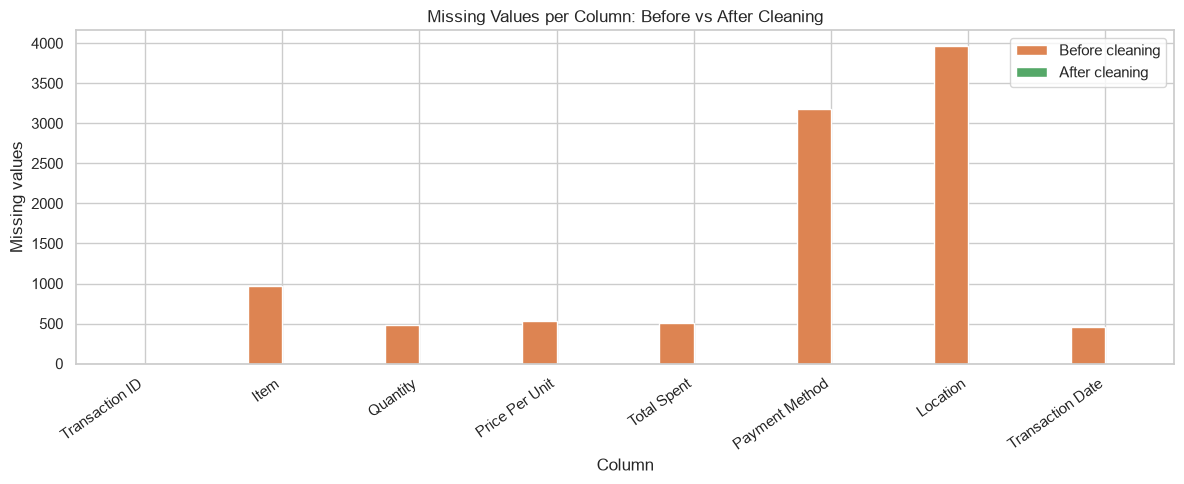

In [9]:
missing_plot = pd.DataFrame({'Before cleaning': missing_before, 'After cleaning': after_missing})
missing_plot.plot(kind='bar', figsize=(12, 5), color=['#dd8452', '#55a868'])
plt.title('Missing Values per Column: Before vs After Cleaning')
plt.xlabel('Column')
plt.ylabel('Missing values')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig(charts_dir / 'missing_values_before_after.png', dpi=180)
plt.show()

## 9. Export Cleaned Dataset and Final Verification

In [10]:
cleaned['Transaction Date'] = cleaned['Transaction Date'].dt.strftime('%Y-%m-%d')
cleaned_output_path = output_dir / 'cleaned_dataset.csv'
cleaned.to_csv(cleaned_output_path, index=False)
reloaded = pd.read_csv(cleaned_output_path)
print(f'Cleaned dataset saved to: {cleaned_output_path.resolve()}')
print(f'Reloaded dimensions: {reloaded.shape}')
print('Reloaded columns:', reloaded.columns.tolist())
print('Reloaded dtypes:')
display(reloaded.dtypes.to_frame('dtype'))
assert cleaned_output_path.exists()
assert reloaded.shape == cleaned.shape
assert reloaded.columns.tolist() == cleaned.columns.tolist()
assert int(reloaded.isna().sum().sum()) == 0
assert int(reloaded.duplicated().sum()) == 0
assert input_path.read_bytes() != cleaned_output_path.read_bytes()
print('Final verification passed: output exists, is reloadable, has no missing values or exact duplicates, and the original remains separate.')

Cleaned dataset saved to: /Users/atifnawaz/Retail_Sales_EDA/Retail_Sales_EDA/DataAnalytics-L1-Task3-DataCleaning/output/cleaned_dataset.csv
Reloaded dimensions: (10000, 8)
Reloaded columns: ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']
Reloaded dtypes:


,dtype
Transaction ID,str
Item,str
Quantity,int64
Price Per Unit,float64
Total Spent,float64
Payment Method,str
Location,str
Transaction Date,str


Final verification passed: output exists, is reloadable, has no missing values or exact duplicates, and the original remains separate.


## Conclusion and Assignment Checklist

- [x] Actual CSV inspected before coding.
- [x] Initial rows, dimensions, columns, types, `info()`, and descriptive statistics displayed.
- [x] Data-quality report calculated before cleaning.
- [x] Missing values handled with documented, column-specific decisions.
- [x] Exact duplicates measured, removed where present, and verified.
- [x] Text, dates, identifiers, quantities, and monetary fields standardized.
- [x] IQR outliers summarized and retained because they are valid business values.
- [x] Before/after quality summary and visualizations created.
- [x] Cleaned CSV exported, reloaded, and verified without overwriting the original.